# Week 5: Problém vlastních čísel

**Assignment:** [![Run in JupyterHub](https://img.shields.io/badge/Run%20in-JupyterHub-F37626?logo=jupyter)](https://hpc.troja.mff.cuni.cz:8000/hub/user-redirect/git-pull?app=lab&repo=https%3A%2F%2Fgitlab.karlin.mff.cuni.cz%2Fznm%2Fcviceni-student&branch=main&subpath=notebooks%2Fassignment%2Fweek-05-eigenvalue-problem.ipynb) [![Download .ipynb](https://img.shields.io/badge/Download-.ipynb-blue)](https://gitlab.karlin.mff.cuni.cz/znm/cviceni-student/-/raw/main/notebooks/assignment/week-05-eigenvalue-problem.ipynb?inline=false) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/num-math/cviceni-student/blob/main/notebooks/assignment/week-05-eigenvalue-problem.ipynb)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Materiály

- [poznámky z přednášky - částečný problém vlastních čísel](https://pages.karlin.mff.cuni.cz/znm/assets/Castecny_problem_cisel.pdf)
- [poznámky z přednášky - úplný problém vlastních čísel](https://pages.karlin.mff.cuni.cz/znm/assets/Uplny_problem_cisel.pdf)
- další materiály
  - kniha [Duintjer Tebbens a kolektiv: Analýza metod pro maticové výpočty](https://cuni.primo.exlibrisgroup.com/discovery/fulldisplay?docid=alma990020832750106986&context=L&vid=420CKIS_INST:UKAZ&lang=cs&search_scope=MyInst_and_CI&adaptor=Local%20Search%20Engine&tab=Everything&query=any,contains,Anal%C3%BDza%20metod%20pro%20maticov%C3%A9%20v%C3%BDpo%C4%8Dty&offset=0) (Kapitola 7)
  - skripta [Barto, Tůma: Lineární algebra](https://www.mff.cuni.cz/data/web/obsah/department_math/ka/skripta_la7.pdf) (Sekce 8.6)
  - bakalářská práce [Cirbus: Implicitní QR algoritmus s násobnými
shifty](https://dl1.cuni.cz/pluginfile.php/1987032/mod_resource/content/1/BCprace_QRalgoritmus.pdf)
  - "objevitelé" vlastních čísel [Cauchy a Sylvester](https://web.archive.org/web/20260614135708/https://old.maa.org/press/periodicals/convergence/math-origins-eigenvectors-and-eigenvalues).

- ***Primární úlohy*** (verze 1 cviko) : A2, A3, A4, B1
- ***Primární úlohy*** (verze 2 cvika) : A1, A2, A3, A4, B1, B3

- ***Úlohy k bonusové části zkoušky*** : A2, A4, B1

- základní ***Learning outcomes*** (cviko, nikoliv přednáška)
  - Umím definovat
    *Rayleighův podíl ([Rayleigh quotient](https://en.wikipedia.org/wiki/Rayleigh_quotient))*
    a vysvětlit jeho roli v kontextu problému vlastních čísel.
  - Umím porovnat mocninnou metodu a Lanczosovu metodu pro aproximaci dominatního vlastního páru.
  - Umím interpretovat Lanczosovu metodu jako zobecnění mocninné metody.

## Intro

[Spektrální rozklad
matice](https://en.wikipedia.org/wiki/Eigendecomposition_of_a_matrix) znáte z
lineární algebry, ale pro jistotu si jej tu připomeneme.
Pro jednoduchost budeme uvažovat jen reálnou matici $A$.
Ale i v takovém případě musíme předpokládat komplexní vlatní páry.

> Nechť matice $A\in \mathbb{R}^{n\times n}$ má vlastní páry
> $(\lambda_i,\mathbf{v}_i)\in\mathbb{C}\times\mathbb{C}^n$,
> $i=1,2,\dotsc,n$, tj.
> \begin{equation*}
  \begin{aligned}
    A\mathbf{v_1} &= \lambda_1\mathbf{v}_1,\\
                  &\vdots \\
    A\mathbf{v_n} &= \lambda_n\mathbf{v}_n,
  \end{aligned}
\end{equation*}
> pro nějaké nenulové vektory
> $\mathbf{v}_1,\dotsc,\mathbf{v}_n\in\mathbb{C}^n$.
> Pokud $\{\mathbf{v}_1,\dotsc,\mathbf{v}_n\}$ tvoří bázi $\mathbb{C}^n$, pak
<a name="eq1"></a>
> \begin{equation*}
  \tag{1}
  A = V\Lambda V^{-1},
\end{equation*}
> kde
> \begin{equation*}
  V = \left[ \mathbf{v}_1, \dotsc , \mathbf{v}_n \right],
  \qquad
  \Lambda = \begin{bmatrix} \lambda_1 \\ & \ddots \\ && \lambda_n \end{bmatrix}.
\end{equation*}
> Matici $V$ lze volit jako ***unitární*** právě tehdy, když $A$ je
> ***normální***, tj. $A^\top A = AA^\top$.
>
> Matici $V$ lze volit jako ***ortogonální*** (reálnou unitární) právě tehdy,
> když $A$ je ***symetrická***, tj. $A = A^\top$. V takovém případě jsou všechna
> vlastní čísla $\lambda_1,\dotsc,\lambda_n$ reálná a existuje množina reálných
> vlastních vektorů $\mathbf{v}_1,\dotsc,\mathbf{v}_n\in\mathbb{R}^n$, která je
> bazí $\mathbb{R}^n$.
>
> Matice, které lze psát ve tvaru [(1)](#eq1) tvoří třídu
> diagonalizovatelných matic. Ne všechny matice jsou diagonalizovatelné, ale
> všechny mají [Jordanův kanonický
> tvar](https://en.wikipedia.org/wiki/Jordan_normal_form), který je zobecněním
> spektrálního rozkladu [(1)](#eq1).

Problém nalezení několika (resp. všech) vlastních párů dané matice se nazývá
***částečný (resp. úplný) problém vlastních čísel.*** V tomto cvičení si projdeme
některé z metod, které se používají pro ***částečný problém vlastních čísel.***

## Část A: Částečný problém vlastních čísel & [Mocninná metoda](https://en.wikipedia.org/wiki/Power_iteration)

### Shrnutí přednášky

Jedná se o metodu pro nalezení ***dominantního vlastního páru***, tj. vlastního
páru odpovídajícího vlastnímu číslu s nejvštší absolutní hodnotou, tj.
$\lambda_{\text{max}}$ takového, že $|\lambda_{\text{max}}| = \max
\{|\lambda_1|, \dots ,|\lambda_n| \}$.

Na přednášce jsme si tuto metodu odvodili na vcelku přímočarém pozorování
***pro diagonalizovatelné matice***. Předpokládejme, že
$A\in\mathbb{R}^{n\times n}$ je diagonalizovatelná a uspořádáme si její vlastní
páry podle absolutní hodnoty vlastních čísel, tj. vezmeme si vlastní páry
$(\mathbf{s}_1,\lambda_1),\dots,(\mathbf{s}_n,\lambda_n)\in\mathbb{C}^n\times\mathbb{C}$
tak, aby

\begin{equation*}
  |\lambda_1| \geq |\lambda_2|  \geq \dots \geq |\lambda_n|.
\end{equation*}

Pak máme spektrální rozklad

\begin{equation*}
  A = \underbrace{\, [\mathbf{s}_1,\dots ,\mathbf{s}_n] \, }_{=: \, S\in \, \mathbb{C}^{n\times n}} \begin{bmatrix} \lambda_1 \\ &\ddots \\ &&\lambda_n \end{bmatrix} \underbrace{\, [\mathbf{s}_1,\dots ,\mathbf{s}_n]^{-1} \, }_{=: \, S^{-1} \in \, \mathbb{C}^{n\times n}} \equiv SDS^{-1}
\end{equation*}

a pro libovolný počáteční vektor $\mathbf{w}_0 \in \mathbb{R}^n$ platí

<a name="eq2"></a>
\begin{equation*}
  \tag{2}
  \begin{aligned}
    A^k \mathbf{w}_{0} &= \left( S D S^{-1} \right)^k \mathbf{w}_0 = S D^k S^{-1} \mathbf{w}_0 = S D^k \begin{bmatrix} c_1 \\ \vdots \\ c_n \end{bmatrix} = \\
    &= [\mathbf{s}_1,\dots ,\mathbf{s}_n] \begin{bmatrix} \lambda_1^kc_1 \\ \vdots \\ \lambda_n^kc_n \end{bmatrix} = c_1\lambda_1^k \mathbf{s}_1 + \dotsc + c_n\lambda_n^k \mathbf{s}_n = \\
    &= \lambda_1^k \left( c_1 \mathbf{s}_1 + c_2 \Bigg( \underbrace{\frac{\lambda_2}{\lambda_1} }_{|\,\cdot \,|\, \leq \,1} \Bigg)^k \mathbf{s}_2 + \dotsc + c_n \Bigg( \underbrace{\frac{\lambda_n}{\lambda_1} }_{|\,\cdot \,|\,  \leq \,1} \Bigg)^k \mathbf{s}_n \right).
  \end{aligned}
\end{equation*}

Jinými slovy, ***pokud*** $|\lambda_1| > |\lambda_2| \geq \dots \geq
|\lambda_n|$ a zároveň $c_1\neq 0$ , ***pak*** bude vektor $A^k\mathbf{w}_0$
konvergovat k dominantnímu vlastnímu vektoru $\mathbf{s}_1$.
Všimněme si, že pokud $A\in\mathbb{R}^{n\times n}$ je unitárně
diagonalizovatelná (tj. normální), lze $S$ volit ortogonální, tj.
$S^{-1}=S^\top$, a tedy $c_1=\mathbf{s}_1^\top\mathbf{w}_0$.
Takže v tomto případě je podmínka $c_1\neq0$ znamená, že vektor $\mathbf{w}_0$
není kolmý na dominantní směr $\mathbf{s}_1$, neboli *$\mathbf{w}_0$ má
komponentu ve směru $\mathbf{s}_1$.*

Idea mocniné metody je založená právě na tomto pozorování. Iterativně
aproximujeme dominantní vlastní vektor $\mathbf{s}_1$ jako

\begin{equation*}
  \begin{gathered}
  \mathbf{w}_0 \mapsto \mathbf{v}_0 := \frac{\mathbf{w}_0}{\|\mathbf{w}_0\|_2} \approx \mathbf{s}_1,\\
  \mathbf{w}_1 := A\mathbf{w}_0 \mapsto \mathbf{v}_1 := \frac{\mathbf{w}_1}{\|\mathbf{w}_1\|_2} \approx \mathbf{s}_1,\\
  \mathbf{w}_2 := A\mathbf{w}_1 \mapsto \mathbf{v}_2 := \frac{\mathbf{w}_2}{\|\mathbf{w}_2\|_2} \approx \mathbf{s}_1,\\
  \mathbf{w}_3 := A\mathbf{w}_2 \mapsto \mathbf{v}_3 := \frac{\mathbf{w}_3}{\|\mathbf{w}_3\|_2} \approx \mathbf{s}_1,\\
  \vdots \\
  \mathbf{w}_k := A\mathbf{w}_{k-1} \mapsto \mathbf{v}_k := \frac{\mathbf{w}_k}{\|\mathbf{w}_k\|_2} \approx \mathbf{s}_1,\\
  \vdots
  \end{gathered}
\end{equation*}

pro nějaký počáteční vektor $\mathbf{w}_0$. Pokud bereme $\mathbf{w}_0$ jako
náhodný vektor z normálního rozdělenmí, pak $c_1\neq 0$ je pro $n>50$ "téméř
jistě pravda" - jinými slovy, je rozumné volit $\mathbf{w}_0$ jako náhodný
vektor jehož prvky odpovídají standardnímu normální rozdělení
$\mathcal{N}(0,1)$.

Pokud mám v $k$-tém kroku aproximaci vlastního vektoru $\mathbf{v}_k\approx
\mathbf{s}_1$, často chci i aproximaci $\mu_k$ vlastního čísla $\lambda_1$.  Na
přednášce jsme viděli, že dobrá aproximace $\mu_k$ je [Rayleighův
podíl](https://en.wikipedia.org/wiki/Rayleigh_quotient) $R(\mathbf{v}_k)$
definován jako

\begin{equation*}
  R(\mathbf{x}) := \frac{\mathbf{x}^\top A\mathbf{x}}{\mathbf{x}^\top\mathbf{x}}
\end{equation*}

a tedy

\begin{equation*}
  \mu_k := R(\mathbf{v}_k) = \frac{\mathbf{v}_k^\top A\mathbf{v}_k}{\mathbf{v}_k^\top\mathbf{v}_k}.
\end{equation*}

### Úloha A1 - analýza konvergence mocninné metody

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Předpokládejme, že $A\in\mathbb{R}^{n\times n}$ je symetrická a máme aproximaci $\mathbf{v}_k\approx \mathbf{s}_1$ (například z mocninné metody) a rozepíšeme si náš vektor $\mathbf{v}_k$ jako $\mathbf{v}_k = \mathbf{s}_1 + \varepsilon_k \mathbf{x}_k$ pro nějaké $\varepsilon_k \gtrsim 0$ a jednotkový vektor $\mathbf{x}_k \in \mathbb{R}^{n}$.

- Formulujte, jak budeme měřit
  - ***chybu*** aproximace $\mathbf{v}_k$ ($\mu_k$) vlastního vektoru $\mathbf{s}_1$ (vlastního čísla $\lambda_1$),
  - ***reziduum*** aproximace ($\mu_k$,$\mathbf{v}_k$) vlastního páru ($\lambda_1,\mathbf{s}_1$),

- Kdybychom "neměli přednášku" nabízí se jednoduchá otázka - jak mám volit aproximaci $\mu_k \approx \lambda_1$ na základě $\mathbf{v}_k$? ***Ta*** přirozená odpověď je zvolit $\mu_k \in \mathbb{R}$ tak, abychom minimalizovali chybu $\| A\mathbf{v}_k - \mu_k \mathbf{v}_k \|^2$ - tedy jako řešení $\arg\min\limits_{\mu \in \mathbb{R}} \, \| A\mathbf{v}_k - \mu \mathbf{v}_k \|^2$. Najděte řešení této minimalizační úlohy.

- Abychom si Rayleighův podíl $R(\mathbf{x})$ trochu osahali, odvodíme si některé základní vlastnosti.
  - Čemu se rovná $R(\mathbf{s}_1 + \varepsilon \mathbf{x})$ pro perturbovaný vlastní vektor (perturbace ve směru $\mathbf{x}$ velikost $\varepsilon$)?
  - Co lze říci o rychlosti konvergence $|\lambda_1 - \mu_k| \rightarrow 0$ za předpokladu, že $\varepsilon_k:= \| \mathbf{v}_k-\mathbf{s}_1 \| \rightarrow 0$, nebo-li $\mathbf{v}_k\rightarrow \mathbf{s}_1$? Porovnejte rychlost konvergencí $\mu_k \rightarrow \lambda_1$ a $\mathbf{v}_k\rightarrow \mathbf{s}_1$.

- [Nápověda & hinty](#head-w05-hinty-a1)

</blockquote>
</div>

### Úloha A2 - konvergence mocninné metody v praxi

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Vezměme si konkrétní příklad

\begin{equation*}
  A = \begin{bmatrix} 4 \\ & 3\\ && 2\\ &&& 1\end{bmatrix} \quad \mathrm{a} \quad \mathbf{w}_0 = \begin{bmatrix} 1 \\ 1 \\ 1 \\ 1\end{bmatrix}.
\end{equation*}

- K jakému vektoru a jak rychle konvergují vektory $\mathbf{v}_k$ z mocninné
  metody? Odhadněte předpokládanou velikost chyby approximace vlastního vektoru
  $\| \mathbf{s}_1 - \mathbf{v}_k \|$ po 70 iteracích na základě
  [(2)](#eq2).

- Změňte matici $A$ na matici $B$ tak, aby byla chyba $\| s_1 - v_k \|$ na
  stejné úrovni již po 35 iteracích (se stejným počátečním vektorem $v_0 =
  [1,1,1,1]^\top$).

- [Nápověda & hinty](#head-w05-hinty-a2)

</blockquote>
</div>

### Úloha A3 - implementace

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Kódění**

Napište funkci `power_method()` podle anotace níže.

</blockquote>
</div>

In [ ]:
def power_method(A,w0,n_iter):
    """
    Pocitame aproximaci dominantniho vlastniho vektoru a dominantniho vlastniho cisla.

    Input
    -------
    A: ctvercova matice n-krat-n
    w0: pocatecni vektor (v R^n)
    n_iter: integer; pocet iteraci mocninne metody

    Output
    -------
    eigenvalues_approx: pole delky "n_iter+1"; "eigenvalues_approx[k]" odpovida aproximaci dominantniho vlastniho cisla po "k"-te iteraci
    eigenvectors_approx: pole rozmeru "n - krat - n_iter+1"; "eigenvectors_approx[:,k]" odpovida aproximaci dominantniho vlastniho vektoru po "k"-te iteraci
    Prvni ulozena data by mela odpovidat "pocatecnimu odhadu", tj. "eigenvectors_approx[:,0] = v0" a "eigenvalues_approx[0] = mu_0"
    Druha ulozena data by mela odpovidat "prvnimu odhadu", tj. "eigenvectors_approx[:,0] = v1" a "eigenvalues_approx[0] = mu_1"
    """
    # Vas kod
    eigenvalues_approx = ...
    eigenvectors_approx = ...

    return eigenvalues_approx, eigenvectors_approx

###############################################################################################
def test_power_method():
    A = np.diag(np.array([2,1,0]))
    w0 = np.ones(A.shape[0])
    n_iter = 10
    eigenvalues, eigenvectors = power_method(A,w0,n_iter)

    assert ( len(eigenvalues) == n_iter+1 ), "output 'eigenvalues_approx' by mel byt vektor delky 'n_iter'."
    assert ( eigenvectors.shape == np.zeros((len(w0),n_iter+1)).shape ), "output 'eigenvectors_approx' by mel byt 2D numpy pole rozmeru 'n'-krat-'n_iter'."
    assert ( np.linalg.norm(eigenvectors[:,0] - w0/np.linalg.norm(w0)) < 1e-13 ), "output 'eigenvectors_approx' by mel splnovat eigenvectors_approx[:,0] = w0."
    assert ( np.abs(eigenvalues[0] - 1) < 1e-13 ), "pro 'A = diag(2,1,0)' a 'w0=[1,1,1]' bzchom meli dostat 'mu_0 = 1'."
    assert ( np.abs(eigenvalues[1] - 1.8) < 1e-13 ), "pro 'A = diag(2,1,0)' a 'w0=[1,1,1]' bzchom meli dostat 'mu_1 = 1.8'."
    return "test_power_method OK"
test_power_method()

### ZÚ - teorie vs praxe

<div style="border-left: 4px solid #8250df; background-color: #fbefff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**❗ ZÚ (semestrální projekt)**

Porovnejte výsledek vaší implementace s predikcemi v úloze A2.
- Odpovídá velikost chyby po 70 iteracích?
- Ověřte, že navrhovaná změna v $A$ vede opravdu ke konvergenci na stejnou
  úroveň chyby už po 35 iteracích.

</blockquote>
</div>

In [ ]:
A = ...
s1 = ...
lambda1_A = ...
lambda2_A = ...

eigenvalues_A_approx, eigenvectors_A_approx = ...
print( "Chyba aproximace vl. vektoru pro A po {} iteracich je: {}".format(n_iter_A, np.linalg.norm(eigenvectors_A_approx[:,-1] - s1)) )

B = ...
lambda1_B =...
lambda2_B = ...

eigenvalues_B_approx, eigenvectors_B_approx = ...
print( "Chyba aproximace vl. vektoru pro B po {} iteracich je: {}".format(n_iter_B, np.linalg.norm(eigenvectors_B_approx[:,-1] - s1)) )


################################################################ Vykreslovani
iters_A = np.arange(0,n_iter_A+1,1)
iters_B = np.arange(0,n_iter_B+1,1)

plt.figure(figsize=(22,10) )

plt.subplot(2,4,1)
for ind in range(0,len(w0)):
    plt.plot(iters_A, eigenvectors_A_approx[ind,:], "o:", markeredgecolor="k", alpha=.8, ms=8, label=r"$(v_k)_i, i$ = {}".format(ind+1))
plt.title(r"slozky vektoru $\mathbf{v}_k$"); plt.ylabel(r"matice $A$"); plt.legend()
plt.subplot(2,4,2)
eigvec_error = np.linalg.norm(eigenvectors_A_approx - s1.reshape((len(w0),1)),  axis=0)
eigvec_error_estimate = (lambda2_A/lambda1_A)**(np.arange(0,n_iter_A+1))
plt.semilogy(iters_A, eigvec_error_estimate, "o-", markeredgecolor="k", alpha=.8, ms=12, label=r"$\left| \frac{\lambda_2}{\lambda_1} \right|^k$" )
plt.semilogy(iters_A, eigvec_error, "o-", markeredgecolor="k", ms=8, label=r"$\| \mathbf{s}_1 - \mathbf{v}_k\|_2$" )
plt.title(r"chyba aproximace vl. vektoru"); plt.legend()
plt.subplot(2,4,3)
residual = np.linalg.norm(A @ eigenvectors_A_approx - eigenvectors_A_approx @ np.diag(eigenvalues_A_approx),  axis=0)
plt.semilogy(iters_A, residual, "o-", markeredgecolor="k", label=r"$\| A\mathbf{v}_k - \mu_k \mathbf{v}_k\|_2$" )
plt.title(r"reziduum aproximace vl. vektoru"); plt.legend()
plt.subplot(2,4,4)
eigval_error = np.abs(lambda1_A - eigenvalues_A_approx)
plt.semilogy(iters_A, eigval_error, "o-", markeredgecolor="k", c='tab:red', label=r"$| \lambda_k - \mu_k|$" )
plt.title(r"chyba aproximace dom. vl. cisla"); plt.legend()

plt.subplot(2,4,5)
for ind in range(0,len(w0)):
    plt.plot(iters_B, eigenvectors_B_approx[ind,:], "o:", markeredgecolor="k", alpha=.8, ms=8, label=r"$(v_k)_i, i$ = {}".format(ind+1))
plt.xlabel(r"iterace $k$"); plt.ylabel(r"matice $B$"); plt.legend()
plt.subplot(2,4,6)
eigvec_error = np.linalg.norm(eigenvectors_B_approx - s1.reshape((len(w0),1)),  axis=0)
eigvec_error_estimate = (lambda2_B/lambda1_B)**(np.arange(0,n_iter_B+1))
plt.semilogy(iters_B, eigvec_error_estimate, "o-", markeredgecolor="k", alpha=.8, ms=12, label=r"$\left| \frac{\lambda_2}{\lambda_1} \right|^k$" )
plt.semilogy(iters_B, eigvec_error, "o-", markeredgecolor="k", ms=8, label=r"$\| \mathbf{s}_1 - \mathbf{v}_k\|_2$" )
plt.xlabel(r"iterace $k$"); plt.legend()
plt.subplot(2,4,7)
residual = np.linalg.norm(B @ eigenvectors_B_approx - eigenvectors_B_approx @ np.diag(eigenvalues_B_approx),  axis=0)
plt.semilogy(iters_B, residual, "o-", markeredgecolor="k", label=r"$\| B\mathbf{v}_k - \mu_k \mathbf{v}_k\|_2$" )
plt.xlabel(r"iterace $k$"); plt.legend()
plt.subplot(2,4,8)
eigval_error = np.abs(lambda1_B - eigenvalues_B_approx)
plt.semilogy(iters_B, eigval_error, "o-", markeredgecolor="k", c='tab:red', label=r"$| \lambda_k - \mu_k|$" )
plt.xlabel(r"iterace $k$"); plt.legend()
plt.show()

### Úloha A4 - puzzle

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Vezmeme si následujících pět diagonálních matic

\begin{equation*}
  \begin{gathered}
  A_1 = \begin{bmatrix} 4 \\ & 4\\ && 2\\ &&& 1\end{bmatrix},
  A_2 = \begin{bmatrix} 4 \\ & 3.9\\ && 3.8\\ &&& 3.7\end{bmatrix},
  A_3 = \begin{bmatrix} -4 \\ & 3\\ && 2\\ &&& 1\end{bmatrix},
  \\
  A_4 = \begin{bmatrix} 4 \\ & -3\\ && 2\\ &&& 1\end{bmatrix},
  A_5 = \begin{bmatrix} 4 \\ & 3.9\\ && 2\\ &&& 1\end{bmatrix}.
  \end{gathered}
\end{equation*}

a pro každou z spočítáme 70 iterací mocninné metody s počátečním vektorem
$\mathbf{w}_0 = [1,1,1,1]$. Spárujte matice $A_1,\dots ,A_5$ s obrázkem níže
(každý řádek odpovídá jedné matici a v každém řádku jsou vykresleny 3 věci -
složky vektoru $\mathbf{v}_k$, chyba $\|\mathbf{s}_1-\mathbf{v}_k\|_2$ a
reziuduum $|A\mathbf{v}_k - \mu_k\mathbf{v}_k|$ pro $k=1,\dots ,70$).
Vysvětlete ***proč*** daný obrázek odpovídá dané matici.

</blockquote>
</div>

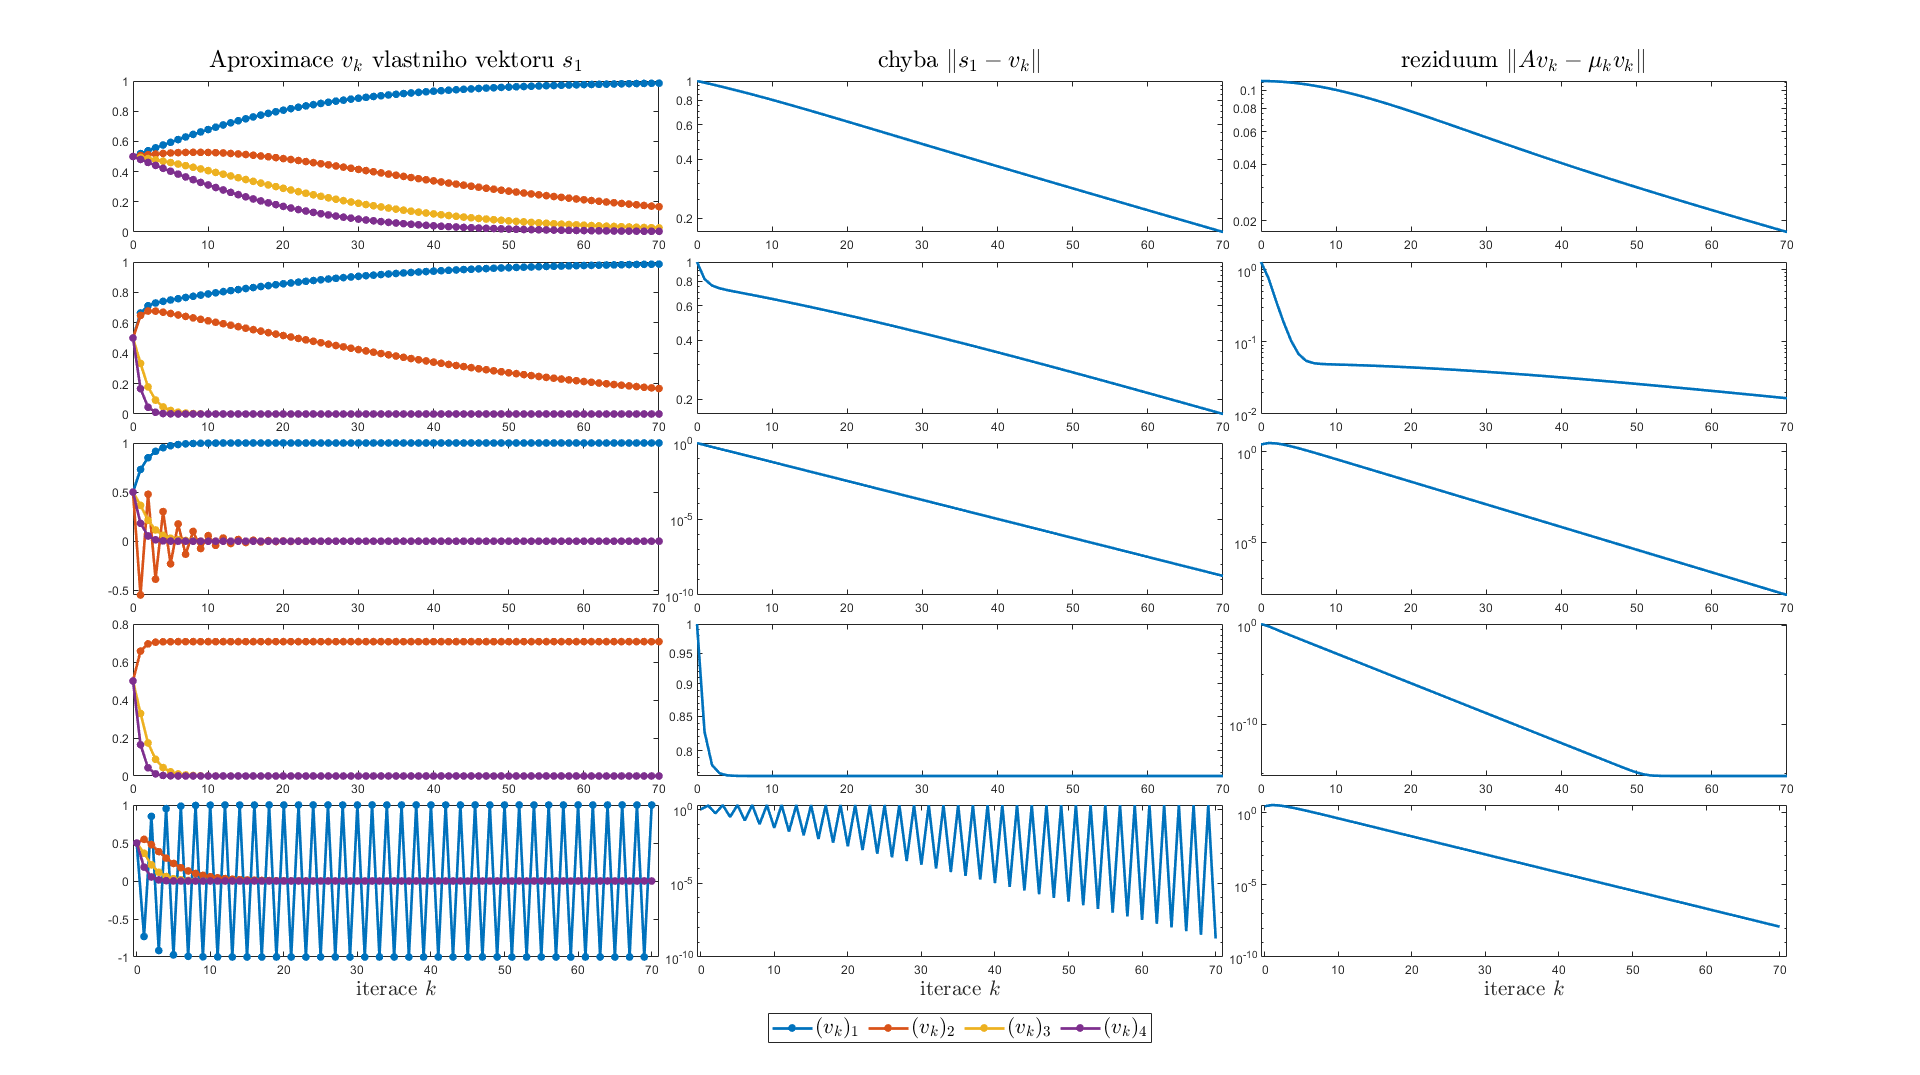

### Úloha A5 - replikování

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Na druhém řádku obrázku výše vidíme, že chyba i reziduum konvergují ve dvou
různých ale stálých režimech - nejprve rychleji (prvních cca pět iterací) a
posléze výrazně pomaleji (od desáté iterace dále).

- Vysvětlete proč tomu tak je pro chybu $\|\mathbf{s}_1-\mathbf{v}_k\|$?
  Zkonstruujte příklady, kde je tento rozdíl ještě více extrémní (tj. rozdíl
  mezi rychlostí konvergence je větší).
- Pro matici $A$ z úlohy A1 najděte nový počáteční vektor
  $\tilde{\mathbf{w}}_0$ tak aby mocninná metoda konvergovala až k druhému
  dominantnímu vlastnímu páru, tj. tak aby $\mathbf{v}_k \rightarrow
  \mathbf{s}_2$.
- Na základě předchozích dvou odpovědí najděte třetí počáteční vektor
  $\hat{\mathbf{w}}_0$, pro který mocninná metoda nejprve zdánlivě konverguje k
  $\mathbf{s}_2$ (prvních několik iterací) ale nakonec zkonverguje k
  $\mathbf{s}_1$ (po sedmdesáti iteracích).

</blockquote>
</div>

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Kódění (navíc, není zapotřebí pro zápočet)**

Adaptujte kód výše tak, aby ilustroval/ověřoval vaše poslední dvě odpovědi.

</blockquote>
</div>

### ZÚ - ["inverse iteration"](https://en.wikipedia.org/wiki/Inverse_iteration)

V mnoha aplikacích ale nechceme nutně aproximovat dominantní vlasntí pár -
potřebujem,e tedy adaptovat mocninou metodu výše tak, aby nám dávala více
volnosti/možností.

Předpokládejme, že máme symetrickou matici $A\in\mathbb{R}^{n\times n}$ a
skalár $\alpha \in \mathbb{R}$ a chceme najít vlastní pár "nejbližší $\alpha$",
tj. vlastní pár odpovídající vl. číslu $\lambda_{\alpha}$, pro které

\begin{equation*}
  |\lambda_{\alpha}-\alpha|
  = \min\limits_{\text{$\lambda$ je vl. číslo $A$}} |\lambda-\alpha|.
\end{equation*}

<div style="border-left: 4px solid #8250df; background-color: #fbefff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**❗ ZÚ (semestrální projekt)**

**Tužka a papír**:

- Začneme s $\alpha=0$: tedy chceme najít vlastní pár odpovídající nejmenšímu
  vlastnímu číslu v absolutní hodnotě - označme ho $\lambda_{\text{min}}$.
  Adaptujte mocninou metodu, aby aproximovala vlastní pár $\lambda_{\text{min}},
  \mathbf{s}_{\text{min}}$ a uveďte předpoklady, za jakých vaše metoda
  konverguje.

- Adaptujte myšlenku výše i pro obecné $\alpha \neq 0$ a formulujte metodu,
  která bude aproximovat vlastní pár $\lambda_{\alpha}, \mathbf{s}_{\alpha}$.
  Opět uveďte předpoklady, za jakých vaše metoda konverguje.

- [Nápověda & hinty](#head-w05-hinty-azu)

</blockquote>
</div>

## Část B: Částečný problém vlastních čísel & [Metody Krylovovských podprostorů](https://en.wikipedia.org/wiki/Krylov_subspace)

### Shrnutí přednášky

Problémy mocninnné metody v praxi jsou hned dva

- pokud chci aproximovat "několik" vlastních čísel, musím nechat mocninnnou
  metody metodu běžet "několikrát",
- pokud má matice $A$ vlastní čísla $\lambda_i$ pro které $|\lambda_i| \approx
  |\lambda_{\text{max}}|$, pak bude mocninnná metoda konvergovat pomalu.

K vylepšení mocninné metody je zásadní následující pozorování.
> Podobně jako ve [cvičení o iteračních metodách](week-02-iterative-methods) u
> stacionárních metod pro řešení $A\mathbf{x}=\mathbf{b}$, mocniná metoda je
> také v jistém smyslu "stacionární" - neadaptujeme naši metodu na základě
> předešlých aproximací. Naopak, $k$-tý krok vypadá naprosto stejně jako první,
> třetí nebo patnáctý, pouze ty příkazy
> - vynásob `vektor na inputu` maticí $A$,
> - znormalizuj výsledný vektor,
> - vypočti aproximaci $\mu$,
>
> provádíme na jiný `vektor na inputu` - konkrétně na ten z předchozí iterace.
> Vektory z iterací $k-2,k-3,\dotsc ,1$ ***už nikdy nepoužíváme***.

Přirozená otázka je, zda-li to nejde lépe - ve [cvičení o iteračních
metodách](week-02-iterative-methods) jsme viděli, že pro stacionární metody to
v jistém smyslu šlo a souviselo to s tzv. Krylovovskými podprostory. Na
přednášce jsme viděli definici tzv. [$k$-tého Krylovova podprostoru
příslušejícího $A$ a
$\mathbf{v}_0$](https://en.wikipedia.org/wiki/Krylov_subspace) jako

\begin{equation*}
  \mathcal{K}_{k}(A,\mathbf{v}_0)
  := \mathrm{span} \left( \mathbf{v}_0, A\mathbf{v}_0, \dotsc , A^{k-1}\mathbf{v}_0  \right).
\end{equation*}

Tato posloupnost vektorů by nám měla být z mocninné metody povědomá - až na
normalizaci se jedná se o jednotlivé aproximace dominatního vlastního vektoru
$\mathbf{s}_1$ z mocninné metody pro počáteční vektor $\mathbf{v}_0$. Pokud
chceme "vylepšit" mocninou metodu, následující pozorování je velmi užitečné.

> V $k$-tém kroku mocninné metody jsme doposud pracovali s vektory, které tvoří
> bázi $\mathcal{K}_{k}(A,\mathbf{v}_0)$, ale rozhodli jsme se vybrat
> aproximaci vlastního vektoru $\mathbf{s}_1$ jako (normalizovaný) poslední
> vektor této báze, místo hledání "v nějakém smyslu nejlepší aproximace
> $\mathbf{s}_1$ z $\mathcal{K}_{k}(A,\mathbf{v}_0)$".

Metody Krylovovských podprostorů v kontextu částečného problému vlastních čísel
slouží právě k nalezení "v nějakém smyslu nejlepší aproximace $\mathbf{s}_1$ z
$\mathcal{K}_{k}(A,\mathbf{v}_0)$".

> My se podíváme pouze na případ, kdy je ***$A$ symmetrická a pozitivně
> definitní*** a s ním související [Lanczosovu
> tridiagonalizaci](https://en.wikipedia.org/wiki/Lanczos_algorithm#).

[Lanczosovu tridiagonalizaci](https://en.wikipedia.org/wiki/Lanczos_algorithm#)
jsme viděli na přednášce a nejde o nic jiného než postup, jak spočítat
ortonormální bázi $\mathcal{K}_k(A,\mathbf{v}_0)$. Jde o upravenou verzi
Gramovy&ndash;Schmidtovy ortogonalizace. Konkrétně por $k$ krocích dostaneme

\begin{equation*}
  \begin{aligned}
    &\underbrace{\, \begin{bmatrix}
    a_{11} & a_{12} & \cdots & \cdots & a_{1n} \\
    a_{21} & a_{22} & \ddots &  & \vdots \\
    \vdots & \ddots & \ddots & \ddots & \vdots \\
    \vdots &  & \ddots & \ddots & \vdots \\
    a_{1n} & \cdots & \cdots & \cdots & a_{nn} \\
    \end{bmatrix} \,}_{= \; A \; \in \; \mathbb{R}^{n\times n}}
    \underbrace{\, \begin{bmatrix}
    & & \\
    & & \\
    & & \\
    \mathbf{v}_0 & \cdots & \mathbf{v}_{k-1} \\
    & & \\
    & & \\
    & & \\
    \end{bmatrix} \,}_{= \; V_k \; \in \; \mathbb{R}^{n\times k}}
    \\
    &=
    \underbrace{\, \begin{bmatrix}
    & & & \\
    & & & \\
    & & & \\
    \mathbf{v}_0 & \cdots & \mathbf{v}_{k-1} & \mathbf{v}_{k} \\
    & & & \\
    & & & \\
    & & & \\
    \end{bmatrix} \,}_{= \; V_{k+1} \; \in \; \mathbb{R}^{n\times (k+1)}}
    \underbrace{\, \begin{bmatrix}
    \alpha_{1} & \beta_{2} & &  \\
    \beta_{2} & \ddots & \ddots &  \\
           & \ddots & \ddots & \beta_{k} \\
           &  & \beta_{k} & \alpha_{k} \\
           &  & & \beta_{k+1} \\
    \end{bmatrix} \,}_{= \; T_{k+1,k} \; \in \; \mathbb{R}^{(k+1)\times k}},
  \end{aligned}
\end{equation*}

kde matice $V_k$ a $V_{k+1}$ mají ortonormální sloupce, které tvoří
ortonormální bázi Krylovových prostorů

\begin{equation*}
\mathcal{K}_k(A,\mathbf{v}_0) = \mathrm{span}(\mathbf{v}_0, \dotsc , \mathbf{v}_{k-1})
\qquad \text{a} \qquad
\mathcal{K}_{k+1}(A,\mathbf{v}_0) = \mathrm{span}(\mathbf{v}_0, \dotsc , \mathbf{v}_{k}).
\end{equation*}

Odtud vidíme, že ***ortogonální projekce na $\mathcal{K}_k(A,\mathbf{v}_0)$***
je dána maticí $V_{k}V_{k}^\top$; viz [hint](#head-w05-hinty-uvodlanczos).

[Lanczosova metoda pro aproximaci vlastních čísel
$A$](https://en.wikipedia.org/wiki/Lanczos_algorithm#Application_to_the_eigenproblem)
pak aproximuje vlastní čísla matice $A$ vlastními páry matice $T_k$.

- Zjevně nikoliv všechny &mdash; $T_k$ má právě $k$ vlastních párů, zatímco $A$ má
  právě $n \gg k$ vlastních párů.
- Pokud $T_k$ má vlastní pár $(\mathbf{r},\theta)$, tj. $T_k \mathbf{r} = \theta
  \mathbf{r}$, pak dostaneme aproximaci vlastního páru $A$ jako
  $(V_k\mathbf{r},\theta)$.

### Úloha B1 - Rayleighův podíl a Lanczosova metoda

Připomínáme, že zde předpokládáme, že ***$A$ je symetrická a pozitivně
definitní.*** Vlastní čísla $A$ tedy můžeme můžeme seřadit tak, že

\begin{equation*}
  0 < \lambda_1\leq \lambda_2 \leq \dotsb \leq \lambda_n.
\end{equation*}

Ne všechny vlastnosti níže jdou přirozeně zobecnit pro $A$ symetrickou a
indefinitní. Pro $A$ obecnou (a Arnoldiho proces namísto Lanczosovy metody) už
lze zobecnit jen naprosté minimum. Opět budeme pracovat s [Rayleighovými
podíly](https://en.wikipedia.org/wiki/Rayleigh_quotient) $R(\mathbf{x}) :=
\tfrac{\mathbf{x}^\top A\mathbf{x}}{\mathbf{x}^\top\mathbf{x}}$.

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Ukažte, že platí

- $\lambda_n = \max\limits_{\mathbf{x}\in \mathbb{R}^n, \, \mathbf{x}\neq 0} R(\mathbf{x})$,
- $\lambda_1 = \min\limits_{\mathbf{x}\in \mathbb{R}^n, \, \mathbf{x}\neq 0} R(\mathbf{x})$.

> Tato vlastnost ukazuje na jeden ze způsobů, jak rozumět optimalitě výše.

</blockquote>
</div>


<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Mějme ortonormální bázi $\{\mathbf{v}_0,\dotsc ,\mathbf{v}_{k-1}\}$ prostoru
$\mathcal{K}_k(A,\mathbf{v}_0)$ a označme $V_k=[\mathbf{v}_0,\dotsc
,\mathbf{v}_{k-1}] \in \mathbb{R}^{n\times k}$. Navíc si očíslujeme a seřadíme
vlastní čísla $T_k$ podle velikosti, tj.

\begin{equation*}
  \theta_{1}\leq \theta_2 \leq \dotsc \leq \theta_k.
\end{equation*}

- Ukažte, že $T_k$ je také pozitivně definitné a tedy $\theta_k >0$.
- Spočtěte $\max\limits_{\mathbf{x}\in  \mathcal{K}_k(A,\mathbf{v}_0), \,
  \mathbf{x}\neq 0} R(\mathbf{x})$ a následně také $\min\limits_{\mathbf{x}\in
  \mathcal{K}_k(A,\mathbf{v}_0), \, \mathbf{x}\neq 0} R(\mathbf{x})$.
- Ukažte, že platí $\lambda_1 \leq \theta_1$ a $\theta_k \leq \lambda_n$ a
  tedy $\theta_1,\dotsc,\theta_k \in [\lambda_1,\lambda_n]$.

</blockquote>
</div>

### Úloha B2 - Mocniná metoda & Lanczos

V Úloze B1 jsme viděli nějaké základní vlastnosti vlastních čísel $T_k$ a
jejich základní porovnání s vlastními čísly $A$. Teď se podíváme na
to jak měřit chybu Lanczosovy metody a mocninné metody.

Připomínáme, že zde předpokládáme, že $A$ je symetrická pozitivně definitní. Ne
všechny vlastnosti níže jdou přirozeně zobecnit pro $A$ symetrickou a
indefinitní. Zároveň připomínáme, že vlastní vektory matice $A$ značíme jako
$\mathbf{s}_1,\dotsc,\mathbf{s}_n$.

Zároveň připomeneme, že pro matice umíme definovat *polynomy matic* pro
libovolnou čtvercovou matici. Například pro $X\in \mathbb{R}^{n\times n}$ a pro
polynom $p(t) := 3t^2-7t+2$ přirozeně zavádíme

\begin{equation*}
p(X) = 3X^2-7X+2I_n.
\end{equation*}

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Začneme jemnou variací/připomenutím [Úlohy B1 ze cvičení o iteračních
metodách](#head-w02-b1). Ukažte, že následující výroky jsou ekvivalentní:

- $\mathbf{x} = p_{k-1}(A) \mathbf{v}_0$ pro nějaký reálný polynom $p_{k-1}$
  stupně nejvýše $k-1$;
- $\mathbf{x} \in \mathcal{K}_k \left( A,\mathbf{v}_0 \right)$.

</blockquote>
</div>


<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Formulace výše nám bude stačit ke kvalitativnímu porovnání Lanczosovy metody a mocninné metody.
Označíme si množinu všech polynomů stupně nejvýše $k$ jako $\mathcal{P}_k$.

- Ukažte, že platí

  \begin{equation*}
    \theta_k
    = \max\limits_{ p_{k-1}  \, \in \, \mathcal{P}_{k-1} } \frac{ \mathbf{v}_0^\top p_{k-1}(A)^\top A p_{k-1}(A) \mathbf{v}_0 }{ \mathbf{v}_0^\top p_{k-1}(A)^\top p_{k-1}(A) \mathbf{v}_0 }.
  \end{equation*}

- Rozepíšeme si vektor $\mathbf{v}_0$ do vlastní báze $A$ $\{ \mathbf{s}_1,\dotsc ,\mathbf{s}_n\}$ jako $\mathbf{v}_0 = c_1\mathbf{s}_1 + \dotsb + c_n\mathbf{s}_n$. Odvoďte z rovnosti výše

  \begin{equation*}
    \theta_k
    = \max\limits_{ p_{k-1}  \, \in \, \mathcal{P}_{k-1} } \frac{ \sum\limits_{i=1}^{n} \lambda_i p_{k-1}(\lambda_i)^2 c_i^2 }{ \sum\limits_{i=1}^{n} p_{k-1}(\lambda_i)^2 c_i^2 }
  \end{equation*}

  a ukažte, že pro chybu $\lambda_n - \theta_k$ platí

  \begin{equation*}
    \lambda_n - \theta_a
    =  \frac{ \sum\limits_{i=1}^{n-1} (\lambda_n-\lambda_i) p_{k-1}^{\text{opt}}(\lambda_i)^2 c_i^2 }{ \sum\limits_{i=1}^{n} p_{k-1}^{\text{opt}}(\lambda_i)^2 c_i^2 },
  \end{equation*}

  kde $p_{k-1}^{\text{opt}}$ je optimální polynom, tedy ten polynom, který
  realizuje maximalizaci. Pokud chceme zkoumat/odhadnout chybu $\lambda_n -
  \theta_k$), co se stane, když nahradíme $p_{k-1}^{\text{opt}}$ jiným polynomem?

- Představme si, že do pravé strany $\lambda_n - \theta_k$ dosadíme opravdu
  jiný polynom $q$, který si můžeme sami vybrat. Jaké hodnoty (velké/malé)
  budeme chtít aby $q$ měl v bodě $\lambda_n$ a v bodech $\lambda_1,\dotsc,
  \lambda_{n-1}$? Takové polynomy se hluboce a dlouho studovali a úzce souvisí s
  Chebyshevovými polynomy, které ještě v semestru potkáme a víc se o nich můžete
  dozvědět na předmětu [NMNV543: Aproximace funkcí](https://numapprox.blogspot.com/).

</blockquote>
</div>


<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Vrátíme se na moment k mocninné metodě a podíváme se na ní ve stejném duchu
jako na Lanczosovu metodu výše. Předpokládejme nyní, že po $k-1$ krocích
mocninné metody máme aproximaci $(\mu_{k-1},\mathbf{v}_{k-1})$.

- Ukažte, že platí $\mathbf{v}_{k-1} = \alpha A^{k-1}\mathbf{v}_0$ pro nějaké $\alpha\neq 0$.

- Ukažte, že platí

  \begin{equation*}
    \mu_{k-1}
    = R(\mathbf{v}_{k-1})
    = \frac{ \sum\limits_{i=1}^{n-1} \lambda_i (\lambda_i)^{2(k-1)} c_i^2 }{ \sum\limits_{i=1}^{n} (\lambda_i)^{2(k-1)} c_i^2 }
  \end{equation*}

  a tedy

  \begin{equation*}
    \lambda_n - \mu_{k-1}
    =  \frac{ \sum\limits_{i=1}^{n-1} (\lambda_n-\lambda_i) (\lambda_i)^{2(k-1)} c_i^2 }{ \sum\limits_{i=1}^{n} (\lambda_i)^{2(k-1)} c_i^2 }.
  \end{equation*}

- Porovnejte odhady chyb pro Lanczosovu metodu a pro mocninnou metodu. Kterou
  metodu byste v praxi použili a proč?

</blockquote>
</div>

### Úloha B3 - implementace

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Kódění**

Naimplementujte Lanczosovu metodu podle anotace níže.
- Pro výpočet vlastních čísel $T_k$ dopručujeme použít funkci
  [`np.linalg.eigh()`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html).
  Tato funkce předpokládá, že matice na vstupu je hermitovská a tedy má reálné
  spektrum. Tím pádem na outputu `np.linalg.eigh()` jsou vlastní páry již
  seřazeny od nejmenšího (nejblíže $-\infty$) po největší (nejblíže $+\infty$).

</blockquote>
</div>

In [ ]:
def lanczos_eigenpairs(A,w0,k):
    """
    Pocitame aproximaci $k$ vlastnich paru matice $A$.

    Input
    -------
    A: ctvercova matice n-krat-n
    w0: pocatecni vektor (v R^n)
    k: integer; pocet vlastnichparu, zaroven kontroluje kvalitu aproximace

    Output
    -------
    eigenvalues_approx: pole delky "k"; "eigenvalues_approx[i]" odpovida "i"-temu vlastnimu cislu theta_i matice T_k z Lanczosovi tridiagonalizace.
                                        Stejne jako vyse "eigenvalues_approx[0] <= ... <= eigenvalues_approx[k-1]"
    eigenvectors_approx: pole rozmeru "n - krat - k"; "eigenvectors_approx[:,i]" odpovida aproximaci vlastniho vektoru "A" na zaklade "i"-teho vlastniho paru matice T_k (odpovidajiciho theta_i)

    Output musi splnovat:
      - "A * eigenvectors_approx[:,i] == eigenvalues_approx[i] * eigenvectors_approx[:,i]"
      - "eigenvalues_approx[0] <= ... <= eigenvalues_approx[-1]"
    """
    # Vas kod
    return

########################################################################################################
def test_lanczos_eigenpairs():
    n = 15
    k = 7
    r = np.random.rand(n,n)
    A = np.eye(n)*5*n + r + r.T
    v0 = np.ones(A.shape[0])
    eigenvalues_k, eigenvectors_k = lanczos_eigenpairs(A,v0,k)
    assert ( len(eigenvalues_k) == k ), "output 'eigenvalues_approx' by mel byt vektor delky 'k' (je delky {} pro k={}).".format(len(eigenvalues_k),k)
    assert ( eigenvectors_k.shape == (n,k) ), "output 'eigenvectors_approx' by mela byt matice 'n-krat-k' (ma rozmery {} pro n={}, k={}).".format(eigenvectors_k.shape,n,k)

    A = np.diag(np.array([3,2,1]))
    v0 = np.ones(A.shape[0])
    n = A.shape[0]
    ### primy vypocet by nam mel dat (overeno Wolframem):
    #########  v0 = 1/sqrt(3) [1,1,1]
    #########  v1 = 1/sqrt(2) [1,0,-1]
    #########  v2 = sqrt(2)/(2*sqrt(3)) [1,-2,1]
    #########  v3 = [0,0,0]
    #########  T_{3,2} = [ [2,sqrt(2/3)] , [sqrt(2/3),2] , [0,sqrt(3)/3] ] a tedy theta_1 = 2-sqrt(2/3) & theta_2 = 2+sqrt(2/3)
    #########  T_{4,3} = [ [2,sqrt(2/3),0] , [sqrt(2/3),2,sqrt(3)/3] , [0,sqrt(3)/3,2], [0,0,0] ] a mame "T_{3,3} ma stejna vl. cisla jako A" & vl. vektory jsou ve smerech [1,1] a [1,-1]

    k = 1
    eigenvalues_k, eigenvectors_k = lanczos_eigenpairs(A,v0,k)
    assert ( len(eigenvalues_k) == k ), "output 'eigenvalues_approx' by mel byt vektor delky 'k' (je delky {} pro k={}).".format(len(eigenvalues_k),k)
    assert ( eigenvectors_k.shape == (n,k) ), "output 'eigenvectors_approx' by mela byt matice 'n-krat-k' (ma rozmery {} pro n={}, k={}).".format(eigenvectors_k.shape,n,k)
    assert ( np.abs(eigenvalues_k - 2) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvalues_approx' (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"
    assert ( np.linalg.norm(eigenvectors_k - 1/np.sqrt(3)*np.array([1,1,1])) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvectors_approx' (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"

    k = 2
    eigenvalues_k, eigenvectors_k = lanczos_eigenpairs(A,v0,k)
    assert ( len(eigenvalues_k) == k ), "output 'eigenvalues_approx' by mel byt vektor delky 'k' (je delky {} pro k={}).".format(len(eigenvalues_k),k)
    assert ( eigenvectors_k.shape == (n,k) ), "output 'eigenvectors_approx' by mela byt matice 'n-krat-k' (ma rozmery {} pro n={}, k={}).".format(eigenvectors_k.shape,n,k)
    assert ( np.linalg.norm( np.sort(eigenvalues_k) - np.array([2-np.sqrt(2/3),2+np.sqrt(2/3)])) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvalues_approx' (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"
    V_2 = np.array([ [1,1,1]/np.sqrt(3) , [1,0,-1]/np.sqrt(2) ]).T
    T_eigvecs = np.array([ [1,1]/np.sqrt(2) , [-1,1]/np.sqrt(2) ])
    eigenvectors_correct = V_2 @ T_eigvecs
    assert ( np.linalg.norm(eigenvectors_k[:,0]/eigenvectors_k[0,0] - eigenvectors_correct[:,0]/eigenvectors_correct[0,0]) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvectors_approx' - prvni sloupec (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"
    assert ( np.linalg.norm(eigenvectors_k[:,1]/eigenvectors_k[0,1] - eigenvectors_correct[:,1]/eigenvectors_correct[0,1]) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvectors_approx' - druhy sloupec (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"

    k = 3
    eigenvalues_k, eigenvectors_k = lanczos_eigenpairs(A,v0,k)
    assert ( len(eigenvalues_k) == k ), "output 'eigenvalues_approx' by mel byt vektor delky 'k' (je delky {} pro k={}).".format(len(eigenvalues_k),k)
    assert ( eigenvectors_k.shape == (n,k) ), "output 'eigenvectors_approx' by mela byt matice 'n-krat-k' (ma rozmery {} pro n={}, k={}).".format(eigenvectors_k.shape,n,k)
    assert ( np.linalg.norm( np.sort(eigenvalues_k) - np.array([1,2,3])) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvalues_approx' (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"
    eigenvectors_correct = np.eye(3)[::-1]
    assert ( np.linalg.norm(eigenvectors_k[:,0]/eigenvectors_k[2,0] - eigenvectors_correct[:,0]/eigenvectors_correct[2,0]) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvectors_approx' - prvni sloupec (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"
    assert ( np.linalg.norm(eigenvectors_k[:,1]/eigenvectors_k[1,1] - eigenvectors_correct[:,1]/eigenvectors_correct[1,1]) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvectors_approx' - druhy sloupec (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"
    assert ( np.linalg.norm(eigenvectors_k[:,2]/eigenvectors_k[0,2] - eigenvectors_correct[:,2]/eigenvectors_correct[0,2]) < 1e-10 ), "Pro input 'A=diag(3,2,1), w0=[1,1,1], k=1' je spatny output 'eigenvectors_approx' - druhy treti (spocitejte si to tuzka-a-papir; pro kontrolu jsou vysledky vyse)"
    return "lanczos_eigenpairs() OK"
test_lanczos_eigenpairs()

### ZÚ -  Lanczos v praxi

<div style="border-left: 4px solid #8250df; background-color: #fbefff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**❗ ZÚ (semestrální projekt)**

Experimentujte s volbami parametrů `n`, `k_values` a `matrix_type` v
připraveném skriptu níže.

- Porovnejte mocninnou metodu a Lanczosovu metodu.
- Co lze říci o vlastních číslech matice $T_n$ a jak to odpovídá teorii
  odvozené výše?

</blockquote>
</div>

<details style="border-left: 4px solid #57606a; background-color: #f6f8fa; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<summary style="cursor: pointer;">

**ℹ️ Detaily k parametru "matrix_type"**

</summary>

- `matrix_type = "LinearniSpektrum"` odpovídá matici dané velikost `n`, která
  je SPD a její vlastní čísla $\lambda_1, \lambda_2, ..., \lambda_n$ jsou
  rovnoměrně rozdělené body na intervalu $(1,100)$.

- `matrix_type = "LogLinearniSpektrum"` odpovídá matici dané velikost `n`,
  která je SPD a její vlastní čísla $\lambda_1, \lambda_2, ..., \lambda_n$ jsou
  logaritmicky rovnoměrně rozdělené body na intervalu $(1,100)$. Jinak řečeno,
  $\log(\lambda_1), \log(\lambda_2), ..., \log(\lambda_n)$ jsou rovnoměrně
  rozdělené body na intervalu $(\log(1),\log(100)) = (0,2)$.

- `matrix_type = "Difuze"` - odpovídá reálné aplikaci, viz [Úloha A4 ve cvičení
  o iteračních metodách](week-02-iterative-methods). Je SPD a vlastní čísla
  jsou dány jako $\lambda_i = 4*(n+1)^2 * \sin^2( i/(n+1) * \pi/2 )$. Víceméně
  rovnoměrně pokrývají interval, ale jsou "hustší u krajů a řidší uprostřed".

</details>

In [ ]:
#################################################### Funkce generujici testovaci matice
def get_diffusion_matrix(n):
    ''' Vrati matici "A" odpovidajici problemu difuze z cviceni o iteracnich metodach (uloha A4), ktera je SPD a prakticky relevantni '''
    h = 1/(n+1)
    return 1/h**2 * ( 2*np.diag(np.ones(n),0) - np.diag(np.ones(n-1),-1) - np.diag(np.ones(n-1),1) )

def random_spd_matrix(n, cond, log_spectrum=False):
    """ Vrati nesingularni ctvercovou matici A rozmeru "n"-krat-"n" s cislem podminenosti kappa(A) = "cond". """
    rng = np.random.default_rng(123456789123456789) ### tenhle radek zajistuje, ze ty nahodnz cisla jsou vygenerovanz pri kazdem behu stejne (lze smazat)
    A = rng.standard_normal(size=(n, n))
    U,_,_ = np.linalg.svd(A)
    if log_spectrum:
        S = np.diag(np.logspace(np.log10(cond),0, n))
    else:
        S = np.diag(np.linspace(cond, 1, n))
    return U @ S @ U.T
#################################################### Funkce generujici testovaci matice

###################### Volby parametru
n = 30  # velikost matice "A"
k_values = np.array([2,5,10,15])  # pro ktere "k" vykreslime aproximaci spektra "A" -> 4 integery
matrix_type = "Difuze"  # typ matice "A"; na vyber z "Difuze" , "LinearniSpektrum" , "LogLinearniSpektrum"
# matrix_type = "LinearniSpektrum" - A je SPD matice, jeji vl. cisla lambda_1, lambda_2, ..., lambda_n jsou rovnomerne rozdelene body na intervalu (1,100)
# matrix_type = "LogLinearniSpektrum" - A je SPD matice, jeji vl. cisla lambda_1, lambda_2, ..., lambda_n jsou rovnomerne logaritmicky rozdelene body na intervalu (1,100)
#                                     nebo-li log(lambda_1), log(lambda_2), ..., log(lambda_n) jsou rovnomerne rozdelene body na intervalu (0,2)
# matrix_type = "Difuze" - realna aplikace, viz Uloha A4 v cviceni o iteracnich metodach. Vlastni cisla odpovidaji preskalovanym hodnotam "sin^2", konkretne "lambda_i = 4*(n+1)^2 * sin^2( i/(n+1) * pi/2 )"
#                        tyto vlastni cisl aodpovidaji rozlozeni "hustsi u kraju, ridsi uprostred, ale relativne linearne rovnomerne"
###################### Volby parametru


#################################################### FunVypocet a vykreslovani
if matrix_type == "LinearniSpektrum":
    A = random_spd_matrix(n, 100)
elif matrix_type == "LogLinearniSpektrum":
    A = random_spd_matrix(n, 100, True)
elif matrix_type == "Difuze":
    A = get_diffusion_matrix(n)
eigenvalues_exact, _ = np.linalg.eigh(A)
w0 = np.ones(A.shape[0])

plt.figure(figsize=(22,6) )
plt.suptitle("Aproximace vlastnich cisel v linearnim/logaritmickem meritku. Typ matice '{}'".format(matrix_type))
for ind, k in enumerate(k_values):

    eigenvalues_lanczos, _ = lanczos_eigenpairs(A,w0,k)
    eigenvalues_power, _ = power_method(A,w0,k)

    plt.subplot(2,4,ind+1)
    plt.plot(eigenvalues_exact.real, eigenvalues_exact.imag, "s", lw=0,  markeredgecolor="k", c="tab:blue", alpha=.6, ms=15, label=r"$\lambda_{i}$")
    plt.plot(eigenvalues_lanczos.real, eigenvalues_lanczos.imag, "o", lw=0,  markeredgecolor="k", c="orange", alpha=.8, ms=8, label=r"Lanczos, $k$ = {}".format(k))
    plt.plot(eigenvalues_power[-1].real, eigenvalues_power[-1].imag, "^", lw=0,  markeredgecolor="k", c="tab:green", alpha=.8, ms=8, label=r"MM, $k$ = {}".format(k))
    plt.title(r"$k$ = {}".format(k))
    if ind == 0 :
        plt.ylabel(r"$\mathrm{Im}$")

    plt.subplot(2,4,ind+5)
    plt.semilogx(eigenvalues_exact.real, eigenvalues_exact.imag, "s", lw=0,  markeredgecolor="k", c="tab:blue", alpha=.6, ms=15, label=r"$\lambda_{i}$")
    plt.semilogx(eigenvalues_lanczos.real, eigenvalues_lanczos.imag, "o", lw=0,  markeredgecolor="k", c="orange", alpha=.8, ms=8, label=r"Lanczos, $k$ = {}".format(k))
    plt.semilogx(eigenvalues_power[-1].real, eigenvalues_power[-1].imag, "^", lw=0,  markeredgecolor="k", c="tab:green", alpha=.8, ms=8, label=r"MM, $k$ = {}".format(k))
    plt.xlabel(r"$\mathrm{Re}$")
    if ind == 0 :
        plt.ylabel(r"$\mathrm{Im}$")


ax = plt.gca()
fig = plt.gcf()
line1, = ax.plot(eigenvalues_exact[0].real, eigenvalues_exact[0].imag, 's', alpha=.6, ms=15, color='tab:blue', markeredgecolor='k')
line2, = ax.plot(eigenvalues_lanczos[0].real, eigenvalues_lanczos[0].imag, 'o', alpha=.8, ms=8, color='orange', markeredgecolor='k')
line3, = ax.plot(eigenvalues_power[-1].real, eigenvalues_power[-1].imag, '^', alpha=.8, ms=8, color='tab:green', markeredgecolor='k')
all_handles = [line1, line2, line3]
all_labels = [r'vl. cisla $\lambda_i$',
              r'aproximace $\theta_1,...,\theta_k$ "Lanczos"',
              r'aproximace $\mu_k$ "Mocnina metoda"']
fig.legend(all_handles, all_labels, loc='upper center', bbox_to_anchor=(0.5, 0.05), fancybox=True, shadow=True, ncol=3, fontsize=15)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

print( "Chyba aproximace dom. vl. cisla po {} iteracich Lanczose je: {}".format(k, np.abs(eigenvalues_lanczos[-1] - eigenvalues_exact[-1])/np.abs(eigenvalues_exact[-1]) ))
print( "Chyba aproximace dom. vl. cisla po {} iteracich Mocnine metody je: {}".format(k, np.abs(eigenvalues_power[-1] - eigenvalues_exact[-1])/np.abs(eigenvalues_exact[-1]) ))

### ZÚ - porovnání mocninné metody a Lanczose

<div style="border-left: 4px solid #8250df; background-color: #fbefff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**❗ ZÚ (semestrální projekt)**

**Kódění**: Doplňte kód na porovnání rychlosti konvergence Lanczosovy metody a
mocninné metody pro naše 3 testovací matice.

- Porovnejte konvergenci. Pozorujeme něco nečekaného?

**Kódění**: Na základě předchozí úlohy se zdá, že Lanczosova metoda je vhodná i
pro aproximaci $\lambda_1$. Jakou jinou metodu pro aproximaci $\lambda_1$
známe? Jak byste porovnali rychlost konvergence této metody a Lanczose? Zkuste
obě naimplementovat a ověřit si svojí intuici.

</blockquote>
</div>

In [ ]:
n = 50
k_max = 160

A_lin = random_spd_matrix(n, 100)
A_loglin = random_spd_matrix(n, 100, True)
A_diff = get_diffusion_matrix(n)
w0 = np.ones(n)

# Vas kod: pro k = 1, ..., k_max spocitejte relativni chybu aproximace
# dominantniho vlastniho cisla Lanczosovou a mocninnou metodou pro matice A_lin, A_loglin, A_diff
# a vysledky vykreslete (semilogy) do jednoho obrazku.
...

## Hinty

<a name="head-w05-hinty-a1"></a>
### Hint A1 - jak na Rayleighův podíl

Po přímočarém roznásobení $R(\mathbf{s}_1 + \varepsilon \mathbf{x})$ se bude
hodit rovnost

\begin{equation*}
  \lambda_1 + 2\varepsilon \lambda_1 \mathbf{s}_1^\top\mathbf{x} + \varepsilon^2\mathbf{x}^\top A\mathbf{x}
  = \lambda_1( 1 + 2\varepsilon \mathbf{s}_1^\top\mathbf{x}) + \varepsilon^2\mathbf{x}^\top A\mathbf{x}.
\end{equation*}

Jak se vyvíjí výsledný tvar $R(\mathbf{s}_1 + \varepsilon \mathbf{x})$ pro
$\varepsilon \rightarrow 0$?

<a name="head-w05-hinty-a2"></a>
### Hint A2 - rychlost konvergence

Porovnejte situaci s obecným zápisem [(2)](#eq2). Který člen v
rozepsání uvnitř závorky bude největší, který bude druhý největší, atd.?

<a name="head-w05-hinty-azu"></a>
### Hint ZÚ - inverse iteration

- Pokud bychom našli matici $M$, pro kterou je $\lambda_{\text{min}}$ (tj.  v
  absolutní hodnotě nejmenší vlastní číslo matice $A$) ***dominantním***
  vlastním číslem, pak by stačilo použít mocninou metodu pro $M$.
- Jaká má vlastní čísla matice $A^{-1}$?
- Pro kterou matici $M$ je $\lambda_{\alpha}$ ***nejmenším*** vlastním číslem
  (v absolutní hodnotě)?

<a name="head-w05-hinty-uvodlanczos"></a>
### Lanczosova tridiagonalizace - dovysvětlení pojmů

***Ortogonální projekce do $\mathcal{K}_k(A,\mathbf{v}_0)$ vzhledem k bázi
$\{\mathbf{v}_0,\dotsc,\mathbf{v}_{k-1}\}$*** je dána maticí $V_{k}V_{k}^\top$.

> Ortogonální projekcí myslíme zobrazení, které vektoru $\mathbf{x}\in
> \mathbb{R}^{n}$ přiřadí vektor $\hat{\mathbf{x}}\in \mathbb{R}^{n}$, pro
> který
>
> - $\mathbf{y}\in \mathcal{K}_k(A,\mathbf{v}_0)$ a zároveň
> - $\mathbf{x} - \mathbf{y} \perp \mathcal{K}_k(A,\mathbf{v}_0)$.
>
> Matice $V_{k}V_{k}^\top$ odpovídá složení dvou zobrazení:
>
> - $V_{k}^\top$ přiřadí vektoru $\mathbf{x}\in \mathbb{R}^{n}$ složky jeho
>   ortogonálních projekcí do báze $\{ \mathbf{v}_0, \dotsc , \mathbf{v}_{k-1}\}$
>   (tedy zobrazí $\mathbf{x}\in \mathbb{R}^{n}$ na $k$-dimenzionální vektor
>    souřadnic $\mathbf{y}_k\in \mathbb{R}^{k}$,
>
> - $V_{k}$ přiřadí vektoru souřadnic $\mathbf{y}_k\in \mathbb{R}^{k}$ vektor v
>   $\mathbb{R}^{n}$ z $\mathcal{K}_k(A,\mathbf{v}_0)$.